In [ ]:
!pip install -q torch torchvision captum matplotlib numpy pillow scipy

In [2]:
import io
import time
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as T
from captum.attr import IntegratedGradients, LayerGradCam
from PIL import Image
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
WEIGHTS = models.ResNet50_Weights.IMAGENET1K_V1
IMAGE_URLS = [
    "http://images.cocodataset.org/val2017/000000039769.jpg",
    "http://images.cocodataset.org/val2017/000000000285.jpg",
    "http://images.cocodataset.org/val2017/000000000724.jpg",
    "https://ultralytics.com/images/bus.jpg",
]
SEED = 0
torch.manual_seed(SEED)
print(f"DEVICE = {DEVICE}")

DEVICE = mps


# Model Explainability

An attribution method assigns each input pixel (or region) a share of responsibility for one
output logit. The difficulty is that there is no ground truth: a heat map that *looks* like the
object can be produced by an edge detector that never looked at the model. So every method has
to be judged on two things, its mechanism and a test of **faithfulness**, i.e. whether removing
what it highlights actually changes the prediction.

| Method | Signal | Cost per explanation | Known weakness |
|---|---|---|---|
| Saliency (2014) | $\lvert \partial y_c / \partial x \rvert$ | 1 backward | noisy; saturated units get zero gradient |
| Grad-CAM (2017) | last-conv activations weighted by pooled gradients | 1 backward | coarse (stride 32) |
| Grad-CAM++ (2018) | pixel-wise weighted gradients | 1 backward | same resolution as Grad-CAM |
| Integrated Gradients (2017) | gradient averaged along a path from a baseline | $m$ backward passes | depends on the baseline |
| Occlusion (2014) | score drop when a patch is hidden | one forward per patch | slow; patch size sets the resolution |

All five are written from scratch for a pretrained ResNet-50, checked against Captum, and then
scored with the deletion / insertion test and the weight-randomisation sanity check.

---

# 1) Setup: ResNet-50 on Four Photos

ResNet-50 (torchvision `IMAGENET1K_V1`, 76.1% top-1) on four COCO / Ultralytics photos with
one dominant ImageNet object each. Explanations are always for the model's own top-1 class.

In [3]:
model = models.resnet50(weights=WEIGHTS).eval().to(DEVICE)
categories = WEIGHTS.meta["categories"]
preprocess = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor()])
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


class Normalised(nn.Module):
    """Wrap the classifier so attributions are taken w.r.t. [0, 1] pixels."""

    def __init__(self, net: nn.Module) -> None:
        super().__init__()
        self.net = net

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """(B, 3, 224, 224) in [0, 1] -> logits (B, 1000)."""
        return self.net((x - MEAN) / STD)


clf = Normalised(model).eval()
images = []
for url in IMAGE_URLS:
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    img = Image.open(io.BytesIO(urllib.request.urlopen(req).read())).convert("RGB")
    images.append(preprocess(img))
x_all = torch.stack(images).to(DEVICE)
with torch.no_grad():
    probs = clf(x_all).softmax(1)
targets = probs.argmax(1)
for i, (t, p) in enumerate(zip(targets.tolist(), probs.max(1).values.tolist())):
    print(f"image {i}: top-1 '{categories[t]}' ({p:.2f})")

image 0: top-1 'tabby' (0.79)
image 1: top-1 'brown bear' (1.00)
image 2: top-1 'street sign' (0.99)
image 3: top-1 'minibus' (0.58)


# 2) The Math

**Saliency.** $S = \max_{\text{channel}} \lvert \nabla_x y_c \rvert$: the local linear
sensitivity of the logit $y_c$ to each pixel.

**Grad-CAM.** For the last convolutional feature map $A \in \mathbb{R}^{K \times h \times w}$,

$$\alpha_k = \frac{1}{hw}\sum_{i,j} \frac{\partial y_c}{\partial A_{k,ij}}, \qquad
L_{\text{CAM}} = \text{ReLU}\Big(\sum_k \alpha_k A_k\Big),$$

upsampled from $7 \times 7$ to the input. When the head is global average pooling + linear (as
in ResNet), $\alpha_k$ is exactly the class weight $w_{c,k}/hw$, so Grad-CAM reduces to the
original CAM.

**Grad-CAM++** replaces the uniform average by per-location weights. For an exponential
output $e^{y_c}$ the higher derivatives reduce to powers of the first:

$$\alpha_k = \sum_{i,j} \frac{g_{ij}^2}{2 g_{ij}^2 + \sum_{a,b} A_{k,ab}\, g_{ij}^3}\ \text{ReLU}(g_{ij}),
\qquad g = \partial y_c / \partial A_k .$$

**Integrated Gradients.** With a baseline $x'$ (here a black image),

$$\text{IG}_i = (x_i - x'_i) \int_0^1 \frac{\partial y_c(x' + a(x - x'))}{\partial x_i}\, da
\approx (x_i - x'_i)\, \frac{1}{m}\sum_{k=1}^{m} \frac{\partial y_c(x' + \tfrac{k}{m}(x - x'))}{\partial x_i}.$$

By the fundamental theorem of calculus for path integrals, **completeness** holds:
$\sum_i \text{IG}_i = y_c(x) - y_c(x')$, so the error of the Riemann sum is measurable.

**Occlusion.** Slide a $p \times p$ grey patch with stride $s$ and record
$y_c(x) - y_c(x_{\text{occluded}})$ at the covered pixels, averaged over overlaps.

In [4]:
def normalise_map(a: torch.Tensor) -> torch.Tensor:
    """Scale a (H, W) map to [0, 1]."""
    a = a - a.min()
    return a / (a.max() + 1e-12)


def saliency(x: torch.Tensor, target: int) -> torch.Tensor:
    """x (1, 3, H, W) -> (H, W) max-|gradient| over channels."""
    x = x.clone().requires_grad_(True)
    clf(x)[0, target].backward()
    return x.grad[0].abs().amax(0)


def cam_parts(x: torch.Tensor, target: int) -> tuple[torch.Tensor, torch.Tensor]:
    """Activations A and gradients dy/dA of layer4, each (K, 7, 7), via hooks."""
    store = {}
    layer = model.layer4
    h1 = layer.register_forward_hook(lambda m, i, o: store.update(A=o))
    logit = clf(x)[0, target]
    h1.remove()
    store["G"] = torch.autograd.grad(logit, store["A"])[0]
    return store["A"][0].detach(), store["G"][0]


def grad_cam(x: torch.Tensor, target: int) -> torch.Tensor:
    """Grad-CAM (7, 7) before upsampling."""
    A, G = cam_parts(x, target)
    return F.relu((G.mean(dim=(1, 2), keepdim=True) * A).sum(0))


def grad_cam_pp(x: torch.Tensor, target: int) -> torch.Tensor:
    """Grad-CAM++ (7, 7) with the closed-form weights for an exponential score."""
    A, G = cam_parts(x, target)
    denom = 2 * G**2 + (A * G**3).sum(dim=(1, 2), keepdim=True)
    alpha = G**2 / torch.where(denom != 0, denom, torch.ones_like(denom))
    weights = (alpha * F.relu(G)).sum(dim=(1, 2), keepdim=True)
    return F.relu((weights * A).sum(0))


def upsample(cam: torch.Tensor, size: int = 224) -> torch.Tensor:
    """(h, w) -> (size, size) bilinear."""
    return F.interpolate(
        cam[None, None], size=size, mode="bilinear", align_corners=False
    )[0, 0]

In [5]:
def integrated_gradients(
    x: torch.Tensor, target: int, steps: int = 128, chunk: int = 16
) -> tuple[torch.Tensor, float]:
    """IG w.r.t. a black baseline: attributions (3, H, W) and the completeness gap."""
    baseline = torch.zeros_like(x)
    total = torch.zeros_like(x[0])
    # midpoint Riemann sum over a in (0, 1)
    alphas = (torch.arange(steps, device=x.device) + 0.5) / steps
    for s in range(0, steps, chunk):
        a = alphas[s : s + chunk].view(-1, 1, 1, 1)
        path = (baseline + a * (x - baseline)).requires_grad_(True)
        clf(path)[:, target].sum().backward()
        total += path.grad.sum(0)
    attr = (x - baseline)[0] * total / steps
    with torch.no_grad():
        delta = (clf(x)[0, target] - clf(baseline)[0, target]).item()
    return attr, abs(attr.sum().item() - delta) / abs(delta)


@torch.no_grad()
def occlusion(
    x: torch.Tensor, target: int, patch: int = 32, stride: int = 16
) -> torch.Tensor:
    """Average logit drop at each pixel over all grey patches that cover it. (H, W)."""
    base = clf(x)[0, target]
    H = x.shape[-1]
    positions = [
        (i, j)
        for i in range(0, H - patch + 1, stride)
        for j in range(0, H - patch + 1, stride)
    ]
    drops = torch.zeros(H, H, device=x.device)
    counts = torch.zeros(H, H, device=x.device)
    for s in range(0, len(positions), 64):
        batch = x.repeat(len(positions[s : s + 64]), 1, 1, 1)
        for b, (i, j) in enumerate(positions[s : s + 64]):
            batch[b, :, i : i + patch, j : j + patch] = 0.5
        scores = clf(batch)[:, target]
        for b, (i, j) in enumerate(positions[s : s + 64]):
            drops[i : i + patch, j : j + patch] += base - scores[b]
            counts[i : i + patch, j : j + patch] += 1
    return drops / counts.clamp(min=1)

In [6]:
x0, t0 = x_all[:1], int(targets[0])
start = time.time()
ig_attr, gap = integrated_gradients(x0, t0, steps=128)
print(f"IG, 128 steps: completeness gap {gap:.2%} | {time.time() - start:.1f} s")
for steps in (16, 32):
    print(
        f"IG, {steps:>3} steps: completeness gap "
        f"{integrated_gradients(x0, t0, steps=steps)[1]:.2%}"
    )

ref_ig = IntegratedGradients(clf).attribute(
    x0,
    baselines=torch.zeros_like(x0),
    target=t0,
    n_steps=128,
    method="riemann_middle",
    internal_batch_size=16,
)
print(
    "IG  vs Captum: relative L2 error "
    f"{(ig_attr - ref_ig[0]).norm() / ref_ig.norm():.1e}"
)
ref_cam = LayerGradCam(clf, model.layer4).attribute(
    x0, target=t0, relu_attributions=True
)
ours_cam = grad_cam(x0, t0)
print(f"Grad-CAM vs Captum: max abs error {(ours_cam - ref_cam[0, 0]).abs().max():.1e}")
# for a GAP + linear head, Grad-CAM weights are the class weights / (h w)
A, G = cam_parts(x0, t0)
print(
    "Grad-CAM weights == fc weights / 49: "
    f"{torch.allclose(G.mean((1, 2)), model.fc.weight[t0] / 49, atol=1e-6)}"
)

IG, 128 steps: completeness gap 2.82% | 15.5 s


IG,  16 steps: completeness gap 21.74%


IG,  32 steps: completeness gap 14.45%


IG  vs Captum: relative L2 error 8.4e-08


Grad-CAM vs Captum: max abs error 6.0e-08
Grad-CAM weights == fc weights / 49: True


# 3) Explanations on Four Images

5 methods x 4 images in 84 s


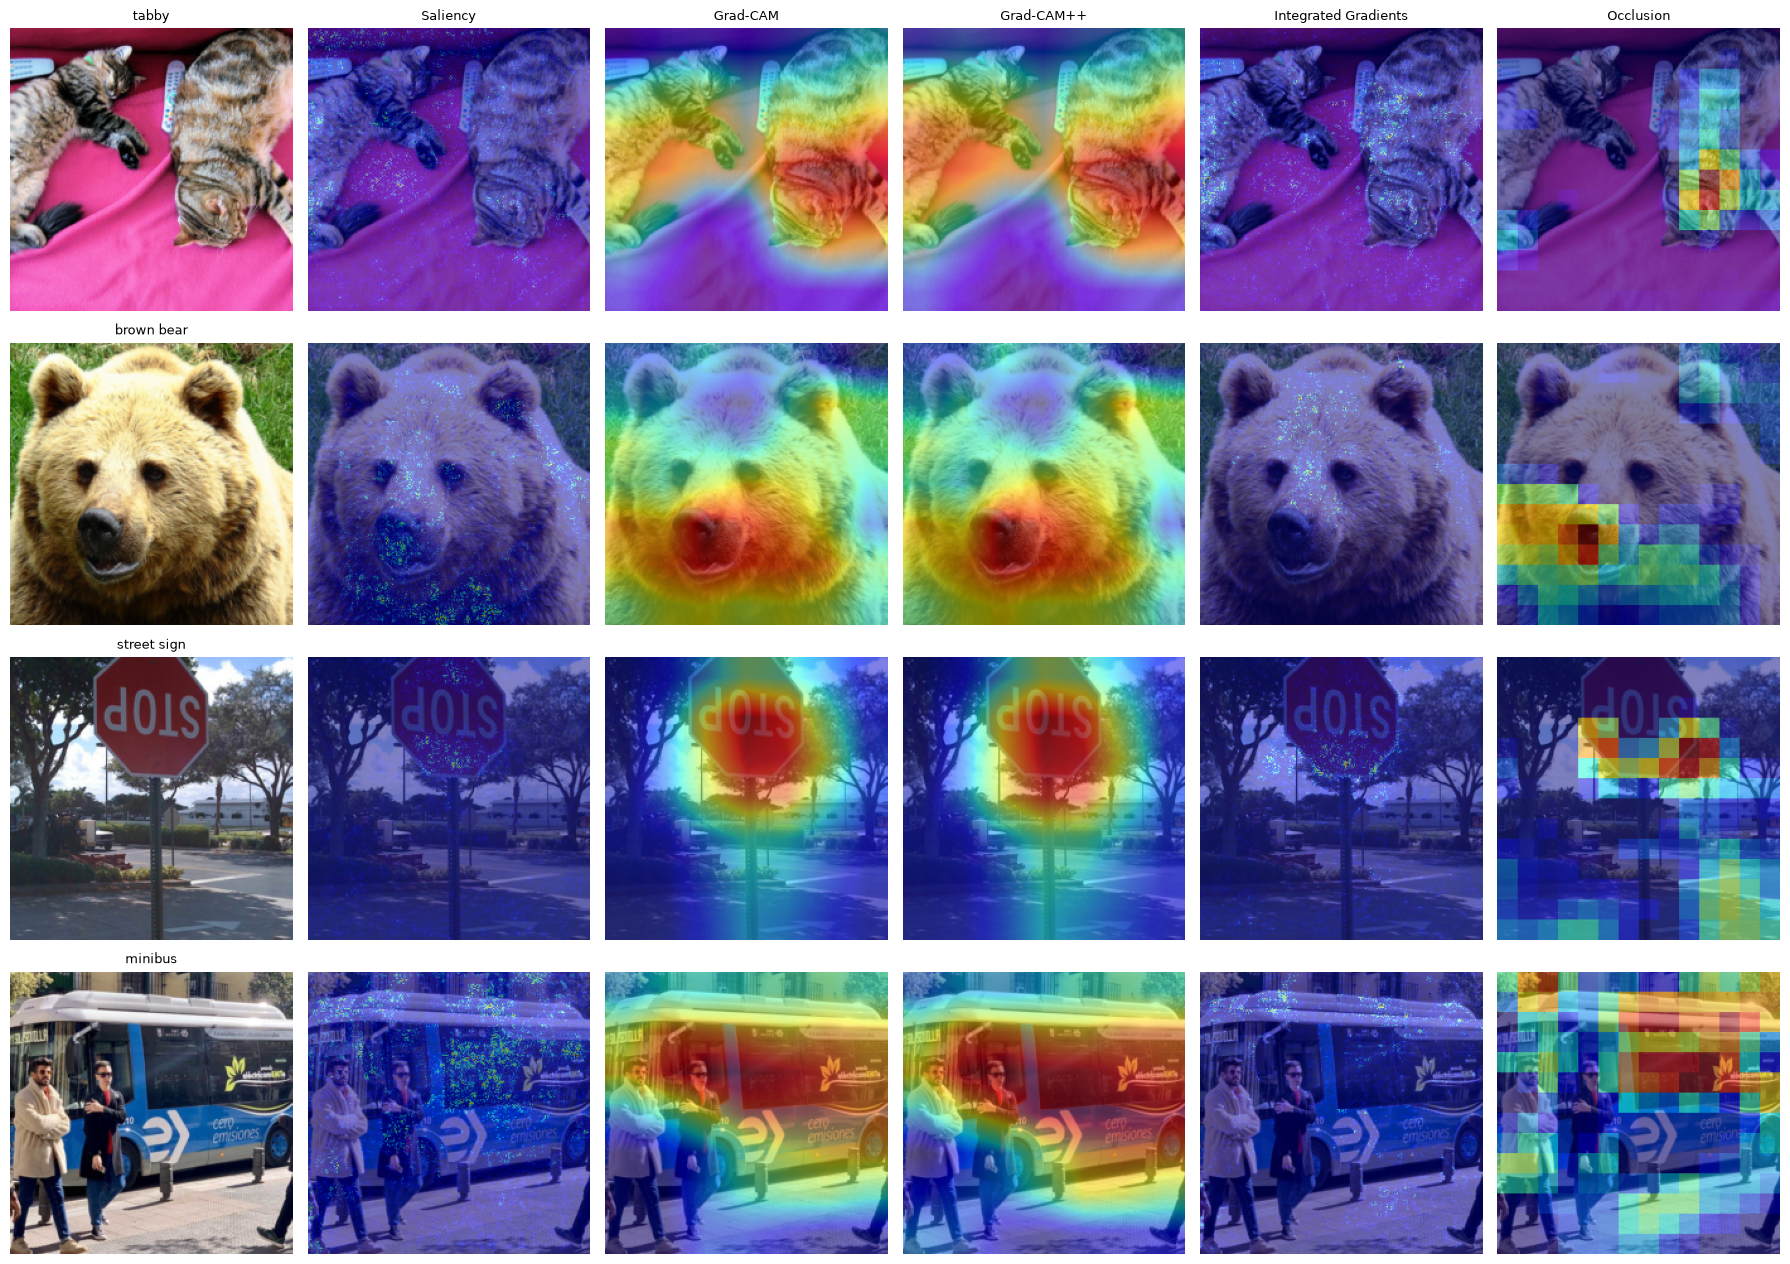

In [7]:
def explain_all(x: torch.Tensor, target: int) -> dict[str, torch.Tensor]:
    """All five maps for one image, each (224, 224) in [0, 1]."""
    ig, _ = integrated_gradients(x, target)
    return {
        "Saliency": normalise_map(saliency(x, target)),
        "Grad-CAM": normalise_map(upsample(grad_cam(x, target))),
        "Grad-CAM++": normalise_map(upsample(grad_cam_pp(x, target))),
        "Integrated Gradients": normalise_map(ig.abs().sum(0)),
        "Occlusion": normalise_map(F.relu(occlusion(x, target))),
    }


start = time.time()
maps = [explain_all(x_all[i : i + 1], int(targets[i])) for i in range(len(x_all))]
print(f"5 methods x {len(x_all)} images in {time.time() - start:.0f} s")
fig, axes = plt.subplots(len(x_all), 6, figsize=(18, 3.2 * len(x_all)))
for row, (x, m) in enumerate(zip(x_all, maps)):
    img = x.permute(1, 2, 0).cpu().numpy()
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(categories[int(targets[row])], fontsize=9)
    for col, (name, a) in enumerate(m.items(), start=1):
        axes[row, col].imshow(img)
        axes[row, col].imshow(a.detach().cpu(), cmap="jet", alpha=0.5)
        axes[row, col].set_title(name if row == 0 else "", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

# 4) Faithfulness: Deletion and Insertion

**Deletion** (Petsiuk et al., 2018): remove pixels in the order the map ranks them (most
important first, replaced by a blurred copy) and track the softmax probability of the target
class. A faithful map makes it collapse quickly, so a **lower** area under the curve is better.
**Insertion** starts from the blurred image and adds pixels back in the same order; a
**higher** area is better. A random ranking is the reference.

In [8]:
@torch.no_grad()
def deletion_insertion(
    x: torch.Tensor, target: int, attr: torch.Tensor, steps: int = 28
) -> tuple[float, float]:
    """AUC of p(target) while deleting / inserting pixels by attribution rank."""
    blurred = T.functional.gaussian_blur(x, kernel_size=31, sigma=10.0)
    # tiny noise breaks ties (flat regions of a map) in random rather than raster order
    order = (
        attr.flatten() + 1e-6 * torch.rand(attr.numel(), device=attr.device)
    ).argsort(descending=True)
    n = order.numel()
    del_x, ins_x = [], []
    for k in torch.linspace(0, n, steps + 1).long().tolist():
        mask = torch.zeros(n, device=x.device)
        mask[order[:k]] = 1
        mask = mask.view(1, 1, *attr.shape)
        del_x.append(x * (1 - mask) + blurred * mask)
        ins_x.append(blurred * (1 - mask) + x * mask)
    p_del = clf(torch.cat(del_x)).softmax(1)[:, target]
    p_ins = clf(torch.cat(ins_x)).softmax(1)[:, target]
    return np.trapezoid(p_del.cpu().numpy(), dx=1 / steps), np.trapezoid(
        p_ins.cpu().numpy(), dx=1 / steps
    )


rows = {name: [] for name in list(maps[0]) + ["Random"]}
for i, m in enumerate(maps):
    x, t = x_all[i : i + 1], int(targets[i])
    for name, a in {**m, "Random": torch.rand(224, 224, device=DEVICE)}.items():
        rows[name].append(deletion_insertion(x, t, a))
print(f"{'method':<22} {'deletion AUC (lower)':>21} {'insertion AUC (higher)':>23}")
for name, vals in rows.items():
    d, ins = np.mean(vals, axis=0)
    print(f"{name:<22} {d:21.3f} {ins:23.3f}")

method                  deletion AUC (lower)  insertion AUC (higher)
Saliency                               0.272                   0.339
Grad-CAM                               0.296                   0.676
Grad-CAM++                             0.298                   0.669
Integrated Gradients                   0.240                   0.430
Occlusion                              0.315                   0.601
Random                                 0.299                   0.307


The two curves disagree, which is why both are reported. Integrated Gradients has the lowest
deletion area: its pixel-level ranking removes exactly the evidence the logit integrates over.
Grad-CAM and Grad-CAM++ have the highest insertion area: their coarse maps restore the whole
object region at once. Coarse maps do poorly on deletion because blurring a large contiguous
block keeps the object's silhouette, and occlusion, whose maps are blocks too, sits at the
random level on deletion despite a strong insertion score.

# 5) Sanity Check: Randomise the Weights

Adebayo et al. (2018) proposed the simplest test: if the model's weights are replaced by random
ones, the explanation should change completely, because the model no longer computes anything
meaningful. A method whose map survives randomisation is explaining the image, not the model.
The last stage (`layer4`) and the classifier are re-initialised top-down and the Spearman rank
correlation with the original map is measured.

In [9]:
original = {name: a.detach().cpu().flatten().numpy() for name, a in maps[0].items()}
trained_state = {k: v.clone() for k, v in model.state_dict().items()}
torch.manual_seed(SEED)
with torch.no_grad():
    for module in [model.fc, *model.layer4.modules()]:
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            nn.init.kaiming_normal_(module.weight)
randomised = explain_all(x_all[:1], int(targets[0]))
model.load_state_dict(trained_state)

print(f"{'method':<22} {'Spearman rho, trained vs randomised':>36}")
for name, a in randomised.items():
    rho = spearmanr(original[name], a.detach().cpu().flatten().numpy()).statistic
    print(f"{name:<22} {rho:36.2f}")

method                  Spearman rho, trained vs randomised


Saliency                                               0.20
Grad-CAM                                              -0.07
Grad-CAM++                                             0.64
Integrated Gradients                                   0.37
Occlusion                                             -0.12


Grad-CAM and occlusion pass: with random top layers their maps are uncorrelated with the
originals. Grad-CAM++ fails, keeping a rank correlation around 0.6. Its weights are built from
$\text{ReLU}(g)$ and positive $\alpha$, so it degenerates to a positive sum of activation
magnitudes, and random convolution features still respond to the image's edges and textures.
Saliency and Integrated Gradients sit in between, because part of a gradient map is the input's
own structure.

# 6) Practical Notes

- **Baselines and steps for IG.** A black baseline gives no attribution to dark pixels; blurred,
  uniform-noise or several averaged baselines (Expected Gradients / GradientSHAP) are common
  alternatives. Always report the completeness gap: it is the only check that the Riemann sum
  has converged. It depends on the weights as much as on the step count. On torchvision's
  `IMAGENET1K_V2` ResNet-50 (trained with heavy augmentation and label smoothing) the gap stayed
  above 45% even at 256 steps, while the `V1` weights used here reach a few percent at 128.
- **Resolution vs faithfulness.** Grad-CAM is stride-32 coarse but stable and cheap; pixel
  methods are sharper but noisier. SmoothGrad (average over noisy copies) and guided variants
  make pixel maps prettier, and guided backprop famously passes the randomisation test badly.
- **Transformers.** For ViTs the analogues are attention rollout, gradient-weighted attention
  and Grad-CAM on the last block's patch tokens reshaped to the grid; register tokens and
  high-norm artefact patches must be removed first.
- **Evaluation.** Deletion/insertion depend on the replacement (blur, grey, noise) because
  removed pixels push the image off the data distribution; ROAR retrains the model after
  removal to avoid this at much higher cost.
- **Libraries.** Captum (PyTorch), `pytorch-grad-cam` and SHAP implement all of the above with
  batching; use them in production and the from-scratch versions to know what they compute.

# 7) Conclusion

| Method | From scratch | Checked against | Strength |
|---|---|---|---|
| Saliency | $\lvert\nabla_x y_c\rvert$ | — | cheapest, pixel-level |
| Grad-CAM | pooled gradients × layer4 activations | Captum `LayerGradCam`; equals CAM for a GAP head | coarse but class-discriminative |
| Grad-CAM++ | closed-form pixel weights | — | covers multiple instances better |
| Integrated Gradients | midpoint Riemann path integral | Captum `IntegratedGradients`; completeness gap | axioms: completeness, sensitivity |
| Occlusion | batched patch sweep | — | model-agnostic, directly causal |

- A heat map is only as good as its faithfulness score: deletion/insertion against a random
  ranking and the randomisation test are cheap enough to run every time.